# Week 4 — Data Quality and Responsible Data Practices: JalanJalanMY

**Input (Topic 3 hand-off):** `data/processed/prepared_text.jsonl` — 303 paragraph-aware chunks from the Tourism Malaysia KL guide (`IDB_PDF_KLD_EN.pdf`), plus `docs/week3_data_inventory.md`.
**Outputs:** `data/prepared_chunks_clean.jsonl`, `data/chunks_clean.pkl`, `docs/week4_validation_failures.csv`, `docs/week4_duplicate_review.csv`, `docs/week4_coverage_by_source.png`.

**Adaptations to the lab template (all documented):**
1. **Cell 0 (adapter):** my Topic 3 pipeline saved `prepared_text.jsonl`, not `prepared_chunks.jsonl` + `chunks.pkl`. Cell 0 converts it into both hand-off files without changing any text.
2. **Cell 4:** the template checks a column `has_bad_char` that Cell 2 never creates (Cell 2 names it `corrupted_char`), so `has_bad_char` is set from `corrupted_char`.
3. **Project-specific fields and rules** are added in Cells 2 and 4 (PDF ligature corruption, glyph-ID garbage, page reference, approved source, source age, hours/fee presence).
4. **A5 applies the triage decisions** (repair ligatures, remove 1 fragment, quarantine unreadable map chunks) before Cell 5, and logs every removed chunk in `docs/week4_quarantine_log.csv`.

**Run order:** upload `prepared_text.jsonl` → Cell 0 → Cell 1 → … → C2 verification.

## Part A — Assess and validate the prepared data

### A0 — Data quality gate plan
| Topic 2 requirement | Required data / evidence | Quality concern | Observable check | Possible decision |
|---|---|---|---|---|
| **FR3 / RAI1** — suggest only attractions from official sources, each with a source reference | Every chunk traceable to an approved official source; readable attraction text | Completeness + consistency + accuracy | `source` present and in the approved list; page reference present; no corrupted characters (including PDF ligature artefacts) | Accept / Correct / Review |
| **NFR2 / FR4 / RAI4** — correct opening hours and fees, dated, for feasibility checks | Opening hours and fees per attraction; source date | Completeness + timeliness | Share of chunks containing hours or prices; source age ≤ 24 months | Accept / Review / Hold |
| **RAI2** — similar plan quality across Penang, Kuala Lumpur, Melaka and Sabah | Official attraction evidence for all four evaluated states | Completeness (coverage) | Chunks per required state | Accept / Hold for missing states |

### Upload the Topic 3 output
Upload `prepared_text.jsonl` (from `data/processed/` in your repo) anywhere in the Colab Files panel, then run Cell 0.

In [1]:
# Cell 0 — Topic 3 hand-off adapter (JalanJalanMY)
# Converts data/processed/prepared_text.jsonl into the two files Topic 4 expects:
# /content/prepared_chunks.jsonl (inspectable) and /content/chunks.pkl (LangChain Documents).
!pip install -q langchain-core
import json, pickle, shutil
from pathlib import Path
from langchain_core.documents import Document

SRC = Path("/content/prepared_text.jsonl")
if not SRC.exists():
    found = [p for p in Path("/content").rglob("prepared_text.jsonl") if "processed" in str(p)] \
            or list(Path("/content").rglob("prepared_text.jsonl"))
    if not found:
        raise FileNotFoundError("Upload data/processed/prepared_text.jsonl from Topic 3 first.")
    shutil.copy(found[0], SRC)
    print("Using:", found[0])

topic3 = [json.loads(line) for line in SRC.open(encoding="utf-8") if line.strip()]
hand_off = [Document(page_content=r["text"],
                     metadata={"source": r["source"], "page": r["page"],
                               "record_id": r["record_id"],
                               "source_sha256": r["source_sha256"],
                               "processing": r["processing"]})
            for r in topic3]

with open("/content/chunks.pkl", "wb") as f:
    pickle.dump(hand_off, f)
with open("/content/prepared_chunks.jsonl", "w", encoding="utf-8") as f:
    for i, d in enumerate(hand_off):
        f.write(json.dumps({"chunk_id": i, "text": d.page_content, "metadata": d.metadata},
                           ensure_ascii=False) + "\n")
Path("/content/data").mkdir(exist_ok=True)
shutil.copy("/content/chunks.pkl", "/content/data/chunks.pkl")
shutil.copy("/content/prepared_chunks.jsonl", "/content/data/prepared_chunks.jsonl")
print("Topic 3 records converted:", len(hand_off))


Topic 3 records converted: 303


In [2]:
# Cell 1 — Topic 4 setup and Topic 3 hand-off verification
!pip install -q pandera pandas matplotlib
import os, re, json, pickle, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa

with open('/content/chunks.pkl', 'rb') as f:
    chunks = pickle.load(f)

prepared_records = []
with open('/content/prepared_chunks.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            prepared_records.append(json.loads(line))

print(f'Compatibility chunks: {len(chunks)}')
print(f'Inspectable JSONL records: {len(prepared_records)}')
if len(chunks) != len(prepared_records):
    raise ValueError('Topic 3 hand-off mismatch: JSONL and PKL chunk counts differ.')
print('Topic 3 hand-off verified.')
print(chunks[0].page_content[:250])
print(chunks[0].metadata)


Compatibility chunks: 303
Inspectable JSONL records: 303
Topic 3 hand-off verified.
1
The Dazzling Capital City
KUALA LUMPUR
Petronas Twin Towers
2
4 DOING THE SIGHTS 
5 Prestigious Landmarks
6 Heritage Sites
10 Places of Worship
12 Themed Attractions
14 TROPICAL ENCLAVES
15 Perdana Botanical Gardens
16 KLCC Park
17 Titiwangsa Lake 
{'source': 'IDB_PDF_KLD_EN.pdf', 'page': None, 'record_id': 'IDB_PDF_KLD_EN-0001', 'source_sha256': '1484ba6f1b3203f2f1f3ec96c86f8bfcc6bf0ec6988610d0b4fe207eb65b76f7', 'processing': 'paragraph-aware-char-500'}


### A2 — Quality inventory (missing, corrupted, noisy)
Lab fields plus project-specific fields: PDF ligature artefacts, chunk starting mid-word, page reference, hours/price presence, and source age (from the Topic 3 data inventory).

In [3]:
# Cell 2 — Build a chunk-quality inventory (lab fields + JalanJalanMY fields)
from datetime import date

# Source facts recorded in docs/week3_data_inventory.md (not invented here)
APPROVED_SOURCES = {'IDB_PDF_KLD_EN.pdf': {'state': 'Kuala Lumpur', 'modified': date(2025, 3, 18)}}
LIGATURE = re.compile(r'/f_|[ﬀ-ﬆ]')
HOURS = re.compile(r'(?i)opening hours|\d{1,2}[.:]\d{2}\s?(?:am|pm)|\b\d{1,2}\s?(?:am|pm)\b')
PRICE = re.compile(r'RM ?\d')

def months_between(d1, d2):
    return (d2.year - d1.year) * 12 + (d2.month - d1.month)

rows = []
for i, chunk in enumerate(chunks):
    text = chunk.page_content or ''
    meta = chunk.metadata or {}
    source = str(meta.get('source', '') or '')
    stripped = text.strip()
    info = APPROVED_SOURCES.get(source, {})
    rows.append({
        'chunk_id': i,
        'source': source,
        'page': meta.get('page', None),
        'text': text,
        'char_count': len(stripped),
        'missing_text': len(stripped) == 0,
        'missing_source': source.strip() == '',
        'corrupted_char': ('\x00' in text) or ('�' in text),
        'noisy_whitespace': bool(re.search(r'\n{4,}| {4,}', text)),
        # --- JalanJalanMY-specific fields ---
        'ligature_artefacts': len(LIGATURE.findall(text)),
        'glyph_id_garbage': bool(re.search(r'/gid\d{5}', text)),
        'starts_mid_word': stripped[:1].islower(),
        'has_page_ref': meta.get('page') is not None,
        'has_hours': bool(HOURS.search(text)),
        'has_price': bool(PRICE.search(text)),
        'source_age_months': months_between(info['modified'], date.today()) if info else -1,
    })

df = pd.DataFrame(rows)
df['has_ligature_artefact'] = df['ligature_artefacts'] > 0

print(df[['chunk_id','source','page','char_count',
          'missing_text','missing_source',
          'corrupted_char','noisy_whitespace']].head())
print(df['char_count'].describe())
print('Missing text:', int(df['missing_text'].sum()))
print('Missing source metadata:', int(df['missing_source'].sum()))
print('Possible corrupted text (\\x00 / \\ufffd):', int(df['corrupted_char'].sum()))
print('Possible noisy whitespace:', int(df['noisy_whitespace'].sum()))
print('--- project-specific ---')
print('Chunks with PDF ligature artefacts:', int(df['has_ligature_artefact'].sum()),
      '| artefacts in total:', int(df['ligature_artefacts'].sum()))
print('Chunks with glyph-ID garbage (/gidNNNNN):', int(df['glyph_id_garbage'].sum()),
      '| chunk ids', df.loc[df['glyph_id_garbage'], 'chunk_id'].min(), '-', df.loc[df['glyph_id_garbage'], 'chunk_id'].max())
print('Chunks starting mid-word/sentence (lowercase first letter):', int(df['starts_mid_word'].sum()))
print('Chunks with a page reference:', int(df['has_page_ref'].sum()))
print('Chunks mentioning opening hours/times:', int(df['has_hours'].sum()),
      '| mentioning an RM price:', int(df['has_price'].sum()))
print('Source age (months):', sorted(df['source_age_months'].unique()))
print('Examples of ligature artefacts:', sorted({m for t in df['text'] for m in re.findall(r'\S*/f_\S*', t)})[:8])


   chunk_id              source  page  char_count  missing_text  \
0         0  IDB_PDF_KLD_EN.pdf  None         499         False   
1         1  IDB_PDF_KLD_EN.pdf  None         500         False   
2         2  IDB_PDF_KLD_EN.pdf  None         499         False   
3         3  IDB_PDF_KLD_EN.pdf  None         499         False   
4         4  IDB_PDF_KLD_EN.pdf  None         500         False   

   missing_source  corrupted_char  noisy_whitespace  
0           False           False             False  
1           False           False             False  
2           False           False             False  
3           False           False             False  
4           False           False             False  
count    303.000000
mean     472.287129
std       94.527371
min       14.000000
25%      499.000000
50%      500.000000
75%      500.000000
max      500.000000
Name: char_count, dtype: float64
Missing text: 0
Missing source metadata: 0
Possible corrupted text (\x00 / \ufff

**Issue classification (A2):**

| Observable issue | Chunks (of 303) | Classification |
|---|---|---|
| PDF ligature artefacts (`/f_i`, `/f_l`, `ﬀ`, `ﬃ`): e.g. `magni/f_icent`, `/f_lagpole` | **148** (276 artefacts) | **Corrupted** — extraction error, repairable |
| Glyph-ID garbage (`/gid00018/gid00038…`), chunks 228–282 | **55** | **Corrupted** — map labels/legend, unreadable as text |
| Shorter than 100 characters | **8** | **Noisy** or **valid short exception** — needs review |
| Starts mid-word/sentence (lowercase first letter) | **189** | **Inconsistent** chunk boundaries (inherited from Topic 3 chunking) |
| No page reference (`page: None`) | **303** | **Missing** provenance detail |
| Mentions opening hours / an RM price | **5** / **1** | **Missing** domain data for NFR2/FR4 |
| Source age | 20 months | **Still uncertain** — within the 24-month rule, but individual facts are undated |
| `\x00` / `\ufffd`, 4+ newlines or spaces, empty text, empty source | 0 | — |

### A3 — Manual inspection

In [4]:
# Cell 3 — Manual inspection
sample = df.sample(min(10, len(df)), random_state=42)
for idx in sample['chunk_id']:
    c = chunks[int(idx)]
    print('\n--- CHUNK', idx, '---')
    print('Source:', c.metadata.get('source','?'), ' Page:', c.metadata.get('page','?'))
    print(c.page_content[:1200])



--- CHUNK 179 ---
Source: IDB_PDF_KLD_EN.pdf  Page: None
ur
www.eqkualalumpur.equatorial.com/
Four Point By Sheraton Klcc
www.marriott.com/en-us/hotels/kulfk-four-
points-kuala-lumpur-city-centre/rooms/

--- CHUNK 228 ---
Source: IDB_PDF_KLD_EN.pdf  Page: None
68
68
6
8
5
H1
H42
H15
H4
H29
H31
H38
H39
H32
H40
S7
S17
H48
H17
H37
H57
H34
H2
H33
H41
H52
H12
H28H55
H23H19
H27
H46
H45
H36
H47
S12
S5
S15
H8
H30
H21
H51
H22
H3
H50
H7
H58
S14
S21
S16
H43H20
H24
H14
H56
H25
H18
H5
H44
H9 H35
H26
H1 1 
H59H60
H61
H62
S3
P30
P35
S6
S13
H10
H13
H3
H4
H6
H53
S4
S1 1 
S9
S8
S10
H54
H49
Dang Wangi
11
9
H16
Tournament
Players Club
(TPC KL)
P36
S20
S19
S18
69
Hotels
/gid00018/gid00038/gid00001 /gid00001 /gid00034/gid00081/gid00076/gid00064/gid00067/gid00064
/gid00021/

--- CHUNK 111 ---
Source: IDB_PDF_KLD_EN.pdf  Page: None
ee outlets and bu stling street bazaars for a range of 
irresistible goods. Look out for great bargains dur ing the Malaysia Super Sale, Malaysia Mega 
Sale and Malaysia Year-End 

**Observations (A3):**

| Observation (sample from Cell 3) | Classification / quality concern | Evidence needed | Decision |
|---|---|---|---|
| Chunks 246 and 268 are strings of `/gid00078/gid00077…` | **Corrupted** extraction — accuracy, completeness | Compare with the city-map pages of the PDF | **Quarantine** (all 55 such chunks) |
| Chunk 228 is map codes (`H1`, `H42`, `S7`, `P30`…) with the heading "Hotels" | **Noisy**, no attraction content | Map legend in the PDF | **Quarantine** (also contains `/gid` text) |
| Chunk 9: `100-metre-high /f_lagpole … proudly /f_lies the Malaysian /f_lag` | **Corrupted** ligatures — accuracy | Same words in the PDF read "flagpole", "flies", "flag" | **Correct** with a deterministic repair |
| Chunk 111: `bu stling street bazaars`, `dur ing`, then the page number `38` and heading `Sensational Shopping` | **Noisy** extraction (split words, page furniture in text) | Compare with page 38 | **Retain** — readable; note for later cleaning |
| Chunk 60 ends the Royal Malaysia Police Museum entry and starts the National Art Gallery entry, with page number `21` in between | **Inconsistent** boundaries — accuracy risk for FR3/RAI1 | Original pages 20–21 | **Retain**, flag for re-chunking by attraction |
| Chunk 179 starts mid-word (`ur`) and lists hotel websites | **Noisy** low-value directory text | Hotel list page | **Retain** (review) — not used for attraction suggestions |
| Chunk 223: Malay phrase list and "Useful Contacts" | Valid, non-attraction content | — | **Retain** |
| Chunks 33 and 119 are readable attraction descriptions but start mid-word (`t was built`, `ontemporary`) | **Inconsistent** boundaries | — | **Retain** |

**🤔 Reflection — an issue that is hard to express as a simple rule:**

**Chunk 60** is the clearest example: it contains the end of one attraction (Royal Malaysia Police Museum) and the start of another (National Art Gallery), with a page number in between. The affected dimensions are **accuracy and consistency**: if retrieval returns this chunk for "National Art Gallery", the planner could attach the wrong description or location to a stop, which breaks FR3/RAI1. A simple rule can count that 189 chunks *start* mid-word, but it cannot tell **whether an attraction's name and its description ended up in different chunks, or whether two attractions share one chunk** — that needs knowledge of where each attraction entry begins and ends. Split words such as `bu stling` are similar: a rule would need a dictionary to tell them apart from real two-word phrases.

### A4 — Validation rules (Pandera)

In [5]:
# Cell 4 — Repeatable validation rules (lab rules + JalanJalanMY rules)
df['has_bad_char'] = df['corrupted_char']   # template checks has_bad_char; Cell 2 names it corrupted_char

schema = pa.DataFrameSchema({
    'chunk_id': pa.Column(int, checks=pa.Check.ge(0), nullable=False),
    'source': pa.Column(str, checks=[
        pa.Check(lambda s: s.str.strip().str.len() > 0, error='source metadata must not be empty'),
        pa.Check.isin(list(APPROVED_SOURCES), error='source not in approved inventory'),
    ], nullable=False),
    'text': pa.Column(str,
        checks=pa.Check(lambda s: s.str.strip().str.len() > 0, error='chunk text must not be empty'),
        nullable=False),
    'char_count': pa.Column(int, checks=pa.Check.ge(100, error='char_count >= 100 (shorter than one sentence)'),
        nullable=False),
    'has_bad_char': pa.Column(bool,
        checks=pa.Check(lambda s: ~s, error='garbled/replacement characters found'), nullable=False),
    # --- JalanJalanMY rules ---
    'has_ligature_artefact': pa.Column(bool,
        checks=pa.Check(lambda s: ~s, error='PDF ligature artefact (/f_ or U+FB00-FB06)'), nullable=False),
    'glyph_id_garbage': pa.Column(bool,
        checks=pa.Check(lambda s: ~s, error='glyph-ID garbage (/gidNNNNN): unreadable map text'), nullable=False),
    'has_page_ref': pa.Column(bool,
        checks=pa.Check(lambda s: s, error='page reference missing (traceability)'), nullable=False),
    'source_age_months': pa.Column(int,
        checks=pa.Check.le(24, error='source older than 24 months'), nullable=False),
}, strict=False)

def run_schema(frame):
    try:
        schema.validate(frame, lazy=True)
        return pd.DataFrame()
    except pa.errors.SchemaErrors as exc:
        return exc.failure_cases.copy()

failure_cases = run_schema(df)
if failure_cases.empty:
    print('All schema rules passed.')
else:
    print(failure_cases[['schema_context','column','check','failure_case','index']].head(12))
print(f'Validation failures: {len(failure_cases)}')

# Save evidence for the report
os.makedirs('/content/docs', exist_ok=True)
failure_cases.to_csv('/content/docs/week4_validation_failures.csv', index=False)


    schema_context        column  \
0           Column    char_count   
385         Column  has_page_ref   
351         Column  has_page_ref   
350         Column  has_page_ref   
349         Column  has_page_ref   
348         Column  has_page_ref   
347         Column  has_page_ref   
346         Column  has_page_ref   
345         Column  has_page_ref   
344         Column  has_page_ref   
343         Column  has_page_ref   
342         Column  has_page_ref   

                                             check  failure_case  index  
0    char_count >= 100 (shorter than one sentence)            32     37  
385          page reference missing (traceability)             0    174  
351          page reference missing (traceability)             0    140  
350          page reference missing (traceability)             0    139  
349          page reference missing (traceability)             0    138  
348          page reference missing (traceability)             0    137  
347          

In [6]:
# Rule summary — failures and percentage of chunks per rule
DECISIONS = {
    'source metadata must not be empty': 'Hard fail',
    'source not in approved inventory': 'Hard fail',
    'chunk text must not be empty': 'Hard fail',
    'char_count >= 100 (shorter than one sentence)': 'Manual review',
    'garbled/replacement characters found': 'Hard fail',
    'PDF ligature artefact (/f_ or U+FB00-FB06)': 'Correct (deterministic repair)',
    'glyph-ID garbage (/gidNNNNN): unreadable map text': 'Hard fail -> quarantine',
    'page reference missing (traceability)': 'Warning (known Topic 3 limitation)',
    'source older than 24 months': 'Warning',
}
summary = []
for rule, decision in DECISIONS.items():
    n = int((failure_cases['check'] == rule).sum()) if not failure_cases.empty else 0
    summary.append({'rule': rule, 'failures': n, 'percent_of_chunks': round(n / len(df) * 100, 1), 'decision': decision})
print(pd.DataFrame(summary).to_string(index=False))
print('\nchar_count < 100 chunk ids:', sorted(df.loc[df['char_count'] < 100, 'chunk_id'].tolist()))


                                             rule  failures  percent_of_chunks                           decision
                source metadata must not be empty         0                0.0                          Hard fail
                 source not in approved inventory         0                0.0                          Hard fail
                     chunk text must not be empty         0                0.0                          Hard fail
    char_count >= 100 (shorter than one sentence)         8                2.6                      Manual review
             garbled/replacement characters found         0                0.0                          Hard fail
       PDF ligature artefact (/f_ or U+FB00-FB06)       148               48.8     Correct (deterministic repair)
glyph-ID garbage (/gidNNNNN): unreadable map text        55               18.2            Hard fail -> quarantine
            page reference missing (traceability)       303              100.0 Warning (

**Rule table (A4):**

| Rule | Condition | Why this rule? / failure being detected | Failures | Decision |
|---|---|---|---|---|
| Text present | `text.strip() != ""` | Empty chunks give no evidence for any suggestion | 0 | Hard fail |
| Source present and approved | `source != ""` and in the Topic 3 inventory | Untraceable or unapproved evidence breaks FR3/RAI1 | 0 | Hard fail |
| Minimum useful length | `char_count >= 100` | About one sentence. Shorter chunks are tail fragments left by paragraph-aware splitting (Topic 3), often page numbers or URL ends | 8 (2.6%) | Manual review |
| No replacement characters | no `\x00` / `\ufffd` | Generic encoding corruption | 0 | Hard fail |
| **No PDF ligature artefacts** | no `/f_` and no U+FB00–FB06 | Broken words (`magni/f_icent`) hurt retrieval and output text | 148 (48.8%) | **Correct** (deterministic repair) |
| **No glyph-ID garbage** | no `/gid` + 5 digits | Map text extracted as glyph IDs is unreadable | 55 (18.2%) | **Hard fail → quarantine** |
| **Page reference present** | `page is not None` | RAI1 traceability to a page | 303 (100%) | Warning — known Topic 3 limitation |
| **Source age** | `source_age_months <= 24` | Guides go out of date; RAI4 | 0 (20 months) | Warning |

**Threshold note:** 100 characters is a warning condition, not proof of bad data — the 8 flagged chunks are reviewed one by one in A5. 24 months matches a roughly two-yearly guide edition cycle; it does not prove that individual facts are current.

### A5 — Triage of validation failures

In [7]:
# A5 — evidence for the flagged cases
for cid in sorted(df.loc[df['char_count'] < 100, 'chunk_id']):
    print(f'chunk {cid} ({df.at[cid, "char_count"]} chars): {chunks[cid].page_content.strip()!r}')
print('\nLigature example — chunk 7 before repair:', repr(re.search(r'\S{0,20}/f_\S*', chunks[7].page_content).group(0)))


chunk 37 (32 chars): 's a short walk from the station.'
chunk 68 (74 chars): '3f7 & 3f8, 3rd Floor, Bangsar Village 2, \nJalan Telawi 1\n Tel: 03 22822180'
chunk 96 (64 chars): 'Megaview Banquet Hall located at 288 metres \nabove ground level.'
chunk 105 (65 chars): 'te to eat at the variety of F&B outlets \ndotting around the area.'
chunk 155 (92 chars): 'with crunchy bean sprouts. Duck’s eggs \nare sometimes added to give it some extra /f_lavour.'
chunk 165 (14 chars): 'bibistro.my\n51'
chunk 176 (61 chars): 'aka is situated about two hours drive \nsouth of Kuala Lumpur.'
chunk 193 (64 chars): 'sleepinglionsuites.com\nStay With Bintang\nhttps://starushotel.com'

Ligature example — chunk 7 before repair: 'magni/f_icent'


| Failed item | Rule triggered | Evidence checked | Interpretation | Decision | Reason |
|---|---|---|---|---|---|
| Chunk 165 (`bibistro.my\n51`, 14 chars) | char_count < 100 | Chunk text: end of a URL + page number 51 | **Defect** — page furniture | **Remove** | No usable content |
| Chunk 68 (74 chars) | char_count < 100 | `3rd Floor, Bangsar Village 2, Jalan Telawi 1, Tel: 03 22822180` (end of the Hammam Spa @ Bangsar entry) | **Valid short exception** — a spa's address and phone | **Retain** | Useful location information |
| Chunk 96 (64 chars) | char_count < 100 | `Megaview Banquet Hall located at 288 metres above ground level.` (chunk 95 is about KL Tower) | **Valid short exception** — a fact about KL Tower | **Retain** | Legitimate information |
| Chunks 37, 105, 155 (32–92 chars) | char_count < 100 | Sentence endings, e.g. `s a short walk from the station.` | **Boundary fragments** of the previous chunk | **Retain**, flag | Content is real; fix by re-chunking later |
| Chunk 176 (61 chars) | char_count < 100 | `aka is situated about two hours drive south of Kuala Lumpur.` — end of the guide's short Melaka day-trip section (chunk 175) | Valid, about **another state** | **Retain**, note for coverage | Legitimate information |
| Chunk 193 (64 chars) | char_count < 100 | Hotel website list | Low-value directory text | **Review further** | Not used for attraction suggestions |
| 148 chunks, e.g. chunk 7 `magni/f_icent` | ligature artefact | All 145 `/f_` cases are followed by `i` or `l`; `ﬀ`/`ﬃ` are Unicode ligatures | **Defect**, deterministic | **Correct** (`/f_`→`f`, NFKC for U+FB00–FB06) | Repair is exact; text otherwise unchanged |
| 55 chunks, 228–282 | glyph-ID garbage | Map labels and legend. Partial decoding test: lowercase = gid+33, capitals = gid+31, `gid00001` = space gives "National Heart Institute", "Prince Court Medical Centre" | **Defect**, possibly recoverable | **Quarantine** (logged in `docs/week4_quarantine_log.csv`) | Mapping for digits and symbols not verified; do not guess |
| All chunks | page reference missing | Topic 3 records `page: null` | Known pipeline limitation | **Retain with warning** | Document-level source still traceable via SHA-256 |

In [8]:
# A5 — apply the triage decisions (correct + remove), then re-validate
import unicodedata

REMOVE = {165: 'removed: page-number + URL tail fragment ("bibistro.my\\n51"), no usable content'}
for cid in df.loc[df['glyph_id_garbage'], 'chunk_id']:
    REMOVE[int(cid)] = 'quarantined: glyph-ID encoded map labels/legend, unreadable without OCR'

def repair_ligatures(text):
    text = text.replace('/f_', 'f')                       # pypdf ligature glyph names: /f_i, /f_l
    return re.sub(r'[ﬀ-ﬆ]', lambda m: unicodedata.normalize('NFKC', m.group(0)), text)  # ﬀ ﬃ ﬄ ﬁ

repaired, removed, n_fixed_chunks = [], [], 0
for i, c in enumerate(chunks):
    if i in REMOVE:
        removed.append({'chunk_id': i, 'reason': REMOVE[i], 'text': c.page_content})
        continue
    new_text = repair_ligatures(c.page_content)
    if new_text != c.page_content:
        n_fixed_chunks += 1
    meta = dict(c.metadata)
    meta['topic4_original_chunk_id'] = i
    meta['topic4_ligatures_repaired'] = new_text != c.page_content
    repaired.append(Document(page_content=new_text, metadata=meta))

print('Removed or quarantined:', len(removed), '| ids:', [r['chunk_id'] for r in removed][:6], '...')
pd.DataFrame([{'chunk_id': r['chunk_id'], 'decision': r['reason'].split(':')[0], 'reason': r['reason'],
               'preview': re.sub(r'\s+', ' ', r['text'])[:160]} for r in removed]).to_csv(
    '/content/docs/week4_quarantine_log.csv', index=False)
print('Saved docs/week4_quarantine_log.csv (removed/quarantined chunks are recorded, not silently dropped)')
print('Chunks with ligatures repaired:', n_fixed_chunks)
print('Chunk 7 after repair:', repr(re.search(r'\S{0,8}magni\S*', repaired[7].page_content).group(0)))
print('Clean corpus size:', len(repaired))

# Re-validate the corrected corpus with the same schema
df_after = df.drop(index=list(REMOVE)).reset_index(drop=True)
df_after['text'] = [c.page_content for c in repaired]
df_after['chunk_id'] = range(len(df_after))
df_after['has_ligature_artefact'] = df_after['text'].str.contains(LIGATURE)
df_after['glyph_id_garbage'] = df_after['text'].str.contains(r'/gid\d{5}')
after = run_schema(df_after)
print('\nFailures after correction, by rule:')
print(after['check'].value_counts().to_string() if not after.empty else 'none')

chunks = repaired   # Cell 5 deduplicates the corrected corpus


Removed or quarantined: 56 | ids: [165, 228, 229, 230, 231, 232] ...
Saved docs/week4_quarantine_log.csv (removed/quarantined chunks are recorded, not silently dropped)
Chunks with ligatures repaired: 148
Chunk 7 after repair: 'magnificent'
Clean corpus size: 247

Failures after correction, by rule:
check
page reference missing (traceability)            247
char_count >= 100 (shorter than one sentence)      7


## Part B — Duplicates, coverage, bias propagation and responsible data

In [9]:
# Cell 5 — Exact hash deduplication with provenance preserved
seen = {}
unique_chunks = []
duplicate_records = []

for chunk in chunks:
    normalized = re.sub(r'\s+', ' ', chunk.page_content.strip())
    h = hashlib.sha256(normalized.encode('utf-8')).hexdigest()
    if h not in seen:
        seen[h] = {
            'metadata': chunk.metadata.copy(),
            'sources': [chunk.metadata.get('source','?')]
        }
        unique_chunks.append(chunk)
    else:
        seen[h]['sources'].append(chunk.metadata.get('source','?'))
        duplicate_records.append({
            'hash': h,
            'duplicate_source': chunk.metadata.get('source','?'),
            'first_source': seen[h]['sources'][0],
            'preview': normalized[:160]
        })

print('Before:', len(chunks))
print('After exact deduplication:', len(unique_chunks))
print('Exact duplicates found:', len(duplicate_records))

os.makedirs('/content/docs', exist_ok=True)
os.makedirs('/content/data', exist_ok=True)
pd.DataFrame(duplicate_records,
             columns=['hash', 'duplicate_source', 'first_source', 'preview']).to_csv(
    '/content/docs/week4_duplicate_review.csv', index=False)

with open('/content/data/chunks_clean.pkl', 'wb') as f:
    pickle.dump(unique_chunks, f)

with open('/content/data/prepared_chunks_clean.jsonl', 'w', encoding='utf-8') as f:
    for i, c in enumerate(unique_chunks):
        record = {
            'chunk_id': i,
            'text': c.page_content,
            'metadata': c.metadata
        }
        f.write(json.dumps(record, ensure_ascii=False) + '\n')

print('Saved cleaned PKL and inspectable JSONL outputs.')


Before: 247
After exact deduplication: 247
Exact duplicates found: 0
Saved cleaned PKL and inspectable JSONL outputs.


In [10]:
# B1 extra — near-duplicate check (word-trigram Jaccard >= 0.5); exact hashing cannot see these
def trigrams(t):
    w = re.findall(r'\w+', t.lower())
    return set(zip(w, w[1:], w[2:]))
grams = [trigrams(c.page_content) for c in unique_chunks]
near = [(i, j, round(len(grams[i] & grams[j]) / len(grams[i] | grams[j]), 2))
        for i in range(len(grams)) for j in range(i + 1, len(grams))
        if grams[i] and grams[j] and len(grams[i] & grams[j]) / len(grams[i] | grams[j]) >= 0.5]
print('Near-duplicate pairs (Jaccard >= 0.5):', len(near), near[:10])


Near-duplicate pairs (Jaccard >= 0.5): 0 []


**B1 finding:** **0 exact duplicates** (247 → 247) and **0 near-duplicate pairs** at word-trigram Jaccard ≥ 0.5. The corpus has a single source, so cross-source duplicates and contradictory versions of the same attraction **cannot be tested yet** — the corpus is not claimed to be fully deduplicated. `docs/week4_duplicate_review.csv` is therefore empty (header only).

### B2 — Representation and coverage

**What adequate coverage means for JalanJalanMY:** every evaluated state has official attraction evidence, and the facts the constraint checker needs (hours, fees) exist for the attractions it may suggest.

| Required area / topic / group | Why must it be covered? | Expected evidence | Actual evidence (247 chunks) | Potential gap? |
|---|---|---|---|---|
| Kuala Lumpur attractions | Evaluated state (RAI2) | Official attraction list | 247 chunks (100%) from the Tourism Malaysia KL guide | No |
| Penang, Melaka, Sabah attractions | Evaluated states (RAI2) | Official attraction list per state | **No source for these states.** Mentions in the KL guide are incidental — Penang (5 chunks): a dish, a restaurant name, an airport; Sabah (6): handicrafts, geography, a tourist office address; Melaka (7): one short day-trip section (A' Famosa, Stadthuys), the rest transport and contacts | **Yes — genuine gap** |
| Opening hours and entry fees | FR4, NFR2, RAI4 | Hours and fee per attraction | **5** chunks mention hours, **1** mentions a price | **Yes** |
| Interest categories (FR1) | Match suggestions to interests | Heritage, shopping, food, nature, family | 56 / 51 / 37 / 34 / 10 chunks (keyword **proxy**) | Weak for theme parks & family |
| Disability access information | FR1 accessibility needs, RAI2 | Wheelchair / step-free / OKU info | **0** chunks ("accessible" only means reachable by transport) | **Yes** |

            source  chunks  percent
IDB_PDF_KLD_EN.pdf     247    100.0


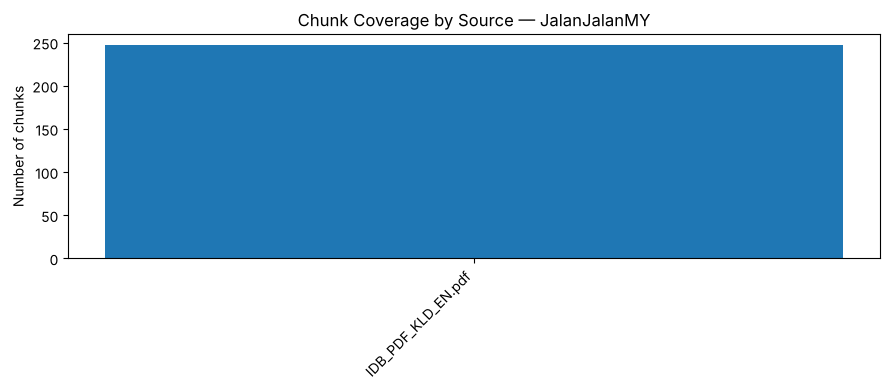

In [11]:
# Cell 6 — Coverage by source
from collections import Counter

source_counts = Counter(c.metadata.get('source','unknown') for c in unique_chunks)
coverage = pd.DataFrame([
    {'source': src, 'chunks': cnt, 'percent': cnt/len(unique_chunks)*100}
    for src, cnt in source_counts.items()
]).sort_values('chunks', ascending=False)

print(coverage.to_string(index=False))

plt.figure(figsize=(9,4))
plt.bar(coverage['source'].astype(str), coverage['chunks'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Number of chunks')
plt.title('Chunk Coverage by Source — JalanJalanMY')
plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_source.png')
plt.show()


required_state  chunks_from_state_source  chunks_mentioning_state
        Penang                         0                        5
  Kuala Lumpur                       247                      136
        Melaka                         0                        7
         Sabah                         0                        6
Mentions are not coverage: read them to see whether they describe attractions (see B2 table).


         topic (proxy)  chunks  percent
    Heritage & culture      56     22.7
              Shopping      51     20.6
                  Food      37     15.0
        Nature & parks      34     13.8
  Theme parks & family      10      4.0
  Opening hours stated       5      2.0
    Entry price stated       1      0.4
Disability access info       0      0.0


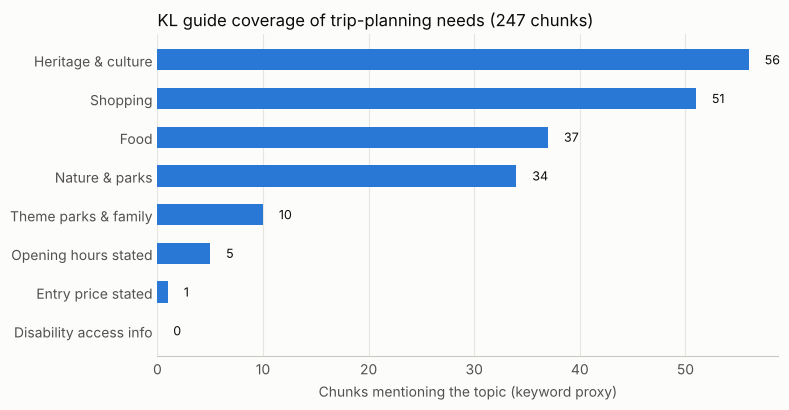

In [12]:
# B2 — domain coverage: (1) required states (source-level metadata), (2) interest topics (keyword PROXY)
REQUIRED_STATES = ['Penang', 'Kuala Lumpur', 'Melaka', 'Sabah']
state_counts = Counter(APPROVED_SOURCES.get(c.metadata.get('source'), {}).get('state', 'unknown') for c in unique_chunks)
STATE_MENTION = {'Penang': r'(?i)\bpenang\b|pulau pinang|george town', 'Kuala Lumpur': r'(?i)kuala lumpur|\bKL\b',
                 'Melaka': r'(?i)\bmelaka\b|\bmalacca\b', 'Sabah': r'(?i)\bsabah\b|kota kinabalu'}
print(pd.DataFrame([{'required_state': s, 'chunks_from_state_source': state_counts.get(s, 0),
                     'chunks_mentioning_state': sum(bool(re.search(STATE_MENTION[s], c.page_content)) for c in unique_chunks)}
                    for s in REQUIRED_STATES]).to_string(index=False))
print('Mentions are not coverage: read them to see whether they describe attractions (see B2 table).')

TOPICS = {  # FR1 interest categories; keyword matches are a proxy, not real metadata
    'Heritage & culture': r'(?i)\b(heritage|temple|mosque|church|colonial|historic|culture|cultural|museum|gallery)\b',
    'Shopping':           r'(?i)\b(shopping|mall|bazaar|market|boutique|retail)\b',
    'Food':               r'(?i)\b(food|cuisine|dish|restaurant|hawker|nasi|satay|cafe|dining|eat)\b',
    'Nature & parks':     r'(?i)\b(park|garden|forest|nature|lake|hill|waterfall|bird)\b',
    'Theme parks & family': r'(?i)\b(theme park|aquarium|zoo|family|kids|children|water park)\b',
    'Opening hours stated': r'(?i)opening hours|\d{1,2}[.:]\d{2}\s?(?:am|pm)|\b\d{1,2}\s?(?:am|pm)\b',
    'Entry price stated': r'RM ?\d',
    'Disability access info': r'(?i)wheelchair|disabled|\boku\b|barrier-free|step-free',
}
topic_counts = {k: sum(bool(re.search(p, c.page_content)) for c in unique_chunks) for k, p in TOPICS.items()}
topic_df = pd.DataFrame([{'topic (proxy)': k, 'chunks': v, 'percent': round(v / len(unique_chunks) * 100, 1)}
                         for k, v in topic_counts.items()])
print(topic_df.to_string(index=False))

# Chart: one series, one hue, direct value labels, recessive grid
SERIES, INK, MUTED, SURFACE = '#2a78d6', '#0b0b0b', '#52514e', '#fcfcfb'
ordered = topic_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
bars = ax.barh(ordered['topic (proxy)'], ordered['chunks'], height=0.55, color=SERIES)
for b, v in zip(bars, ordered['chunks']):
    ax.text(b.get_width() + 1.5, b.get_y() + b.get_height() / 2, str(v), va='center', fontsize=9, color=INK)
ax.set_xlabel('Chunks mentioning the topic (keyword proxy)', color=MUTED)
ax.set_title(f'KL guide coverage of trip-planning needs ({len(unique_chunks)} chunks)', loc='left', color=INK)
ax.grid(axis='x', color='#e6e5e1', linewidth=0.8); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color('#c9c8c3'); ax.tick_params(colors=MUTED, length=0)
plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_topic.png', dpi=150)
plt.show()


**🤔 Reflection — least well-supported required area:**

**Least supported:** Penang and Sabah (no attraction evidence at all) and Melaka (one short day-trip section), followed by disability-access information and opening hours.
- **States — genuine coverage gap.** It comes from source selection: Topic 3 prepared only the KL guide, and the Penang Map & Guide was inspected but not prepared because of its map layout.
- **Hours, fees and accessibility — genuine gap in the source type,** not a chunk-count difference: a promotional brochure does not publish this information, so adding more brochure chunks would not fix it.
- **Theme parks & family (10 chunks) — not yet possible to determine.** The count is a keyword proxy, and KL may simply have fewer such attractions; this needs a check against an official attraction list.

### B3 — Bias risks, propagation and mitigations

| Bias type | Evidence | Likely origin | Potential downstream impact | Mitigation | Test |
|---|---|---|---|---|---|
| **Historical** | The source is a promotional guide from the national tourism board: shopping malls (51 chunks) and big-brand hotels (Marriott, Sheraton, Equatorial) feature heavily | Source — what the publisher chose to promote | Planner keeps suggesting mainstream, commercial stops and rarely small local places | Add other official sources (state boards, heritage bodies, DBKL); monitor diversity of suggested stops | Topic 8: share of suggestions from the most frequent 10 attractions; diversity per plan |
| **Representation** | All 247 chunks come from the KL guide; Penang and Sabah appear only in incidental mentions, Melaka in one short day-trip section | Source selection **and** pipeline (map-layout guide not prepared) | No grounded suggestions outside KL → refusals or ungrounded plans; RAI2 (≤ 10 pp gap) fails | Ingest one official source per evaluated state before Topic 7; layout-aware loader for map guides | Topic 8: per-state feasibility and grounding rates (RAI2) |
| **Measurement** | Hours in 5 chunks, price in 1, disability access 0; topic counts are a keyword proxy; 55 map chunks quarantined (hospitals, tourist info centres, transit map) | Measurement/proxy **and** pipeline (chunking splits entries; extraction loses map text) | Constraint checker cannot verify hours → plans look feasible without evidence; accessibility needs ignored | Structured hours/fee source; attraction-level records; recover glyph-ID text | Topic 8: NFR2 fact accuracy ≥ 95%, NFR3 feasibility, accessibility test profiles |

**🤔 Reflection (two risks with evidence)**

**1. Representation risk — state coverage.**
- *Origin:* source selection in Topic 3 (one guide) amplified by a pipeline decision (the Penang map guide was left out because of its layout).
- *Affected:* tourists planning Penang, Melaka or Sabah trips — including East Malaysia.
- *Propagation:* prepared corpus has no evidence for those states → retrieval returns nothing relevant, or only KL chunks → the generator either refuses or invents stops, which the grounding check would reject.
- *Intervention points:* source selection (add per-state sources) and ingestion (layout-aware extraction).
- *Still to test in Topic 8 (Week 10):* per-state plan feasibility and grounding with the RAI2 ≤ 10 percentage-point gap.

**2. Measurement risk — missing hours, fees and accessibility data.**
- *Origin:* the source type (brochures rarely carry hours) plus a proxy (keyword counts) used to judge coverage.
- *Affected:* every user, most of all elderly or wheelchair users, and users with tight bookings.
- *Propagation:* no hours in the corpus → constraint checker has nothing to verify → plans pass or fail on missing data → users arrive at closed venues or unsuitable places.
- *Intervention points:* data collection (structured hours source such as the data.gov.my Selangor attraction list or attraction websites) and the checker (treat "hours unknown" as a flagged condition, not a pass).
- *Still to test in Topic 8:* NFR2 fact accuracy and NFR3 feasibility, plus accessibility test profiles.

These are **potential** risks from data-level evidence; they do not prove the final system is unfair.

### B4 — Privacy, consent, rights/access and governance

In [13]:
# B4 — personal-data scan (evidence for the governance review)
EMAIL = re.compile(r'[\w.+-]+@[\w-]+\.[\w.]+')
PHONE = re.compile(r'(?:\+?60|\b0)\d{1,2}[- ]?\d{3,4}[- ]?\d{3,4}')
MYKAD = re.compile(r'\b\d{6}-\d{2}-\d{4}\b')   # Malaysian IC number pattern
emails = sorted({e for c in unique_chunks for e in EMAIL.findall(c.page_content)})
print('Distinct e-mail addresses:', len(emails), '| domains:', sorted({e.split('@')[1] for e in emails}))
print('Chunks with phone numbers:', sum(bool(PHONE.search(c.page_content)) for c in unique_chunks))
print('IC-number patterns found:', sum(len(MYKAD.findall(c.page_content)) for c in unique_chunks))


Distinct e-mail addresses: 33 | domains: ['tourism-malaysiadublin.com', 'tourism.g', 'tourism.gov.my']
Chunks with phone numbers: 35
IC-number patterns found: 0


| Governance question | Evidence from JalanJalanMY | Status | Required action / owner |
|---|---|---|---|
| Are the source owner, version/date and provenance traceable? | Tourism Malaysia; PDF modified 18 Mar 2025; SHA-256 `1484ba6f…` in `data/week3_manifest.json`; every chunk keeps `source` and `source_sha256`. **Page numbers are missing.** | OK (document level) / Gap (page level) | Keep page numbers when re-chunking in Topic 7 — Jessie |
| Are rights/access terms known and appropriate for intended use? | Guide states "© Tourism Malaysia. All rights reserved." Publicly downloadable, but publicly accessible ≠ public domain. Current use: coursework only. | **To verify** | Confirm coursework use with the lecturer; keep the repo private; seek permission before any public deployment — Jessie |
| Does the corpus contain personal or sensitive data that is unnecessary for the task? | Scan: 33 distinct e-mail addresses, all institutional tourism-office domains (`tourism.gov.my` and an overseas office domain); 35 chunks with business/office phone numbers; 0 IC-number patterns | **No** — business contact data only | Keep the scan in the pipeline for new sources — Jessie |
| If personal data is collected, is the collection basis / consent / disclosure appropriate? | The corpus is a published institutional document; no personal data is collected. (User conversation data is outside this corpus and covered by RAI5.) | **N/A** | — |
| Are update, superseded-version, retention or removal responsibilities defined? | No process yet for new guide editions or removing superseded versions | **Gap** | Record edition date in the manifest; check the e-brochure portal each semester; replace and re-validate superseded guides — Jessie, before Topic 7 |

## C2 — Verify outputs before committing

In [14]:
# C2 — reload both cleaned artefacts and confirm counts match
with open('/content/data/chunks_clean.pkl', 'rb') as f:
    reloaded = pickle.load(f)
with open('/content/data/prepared_chunks_clean.jsonl', encoding='utf-8') as f:
    reloaded_jsonl = [json.loads(l) for l in f if l.strip()]
print('chunks_clean.pkl:', len(reloaded), '| prepared_chunks_clean.jsonl:', len(reloaded_jsonl))
assert len(reloaded) == len(reloaded_jsonl), 'Clean PKL and JSONL counts differ.'
assert all(r['text'] == d.page_content for r, d in zip(reloaded_jsonl, reloaded)), 'Text differs between PKL and JSONL.'
print('PASS: cleaned PKL and JSONL match.')
for p in ['data/prepared_chunks_clean.jsonl', 'data/chunks_clean.pkl', 'docs/week4_validation_failures.csv',
          'docs/week4_duplicate_review.csv', 'docs/week4_quarantine_log.csv',
          'docs/week4_coverage_by_source.png', 'docs/week4_coverage_by_topic.png']:
    print(f'{p:40} {os.path.getsize("/content/" + p):>8} bytes')


chunks_clean.pkl: 247 | prepared_chunks_clean.jsonl: 247
PASS: cleaned PKL and JSONL match.
data/prepared_chunks_clean.jsonl           198480 bytes
data/chunks_clean.pkl                      167656 bytes
docs/week4_validation_failures.csv          36811 bytes
docs/week4_duplicate_review.csv                43 bytes
docs/week4_quarantine_log.csv               13949 bytes
docs/week4_coverage_by_source.png           18622 bytes
docs/week4_coverage_by_topic.png            62300 bytes


In [15]:
# C2 — download the Topic 4 outputs (Colab files disappear when it disconnects)
import shutil
from pathlib import Path
stage = Path('/content/week4_download')
if stage.exists():
    shutil.rmtree(stage)
for p in ['data/prepared_chunks_clean.jsonl', 'data/chunks_clean.pkl', 'docs/week4_validation_failures.csv',
          'docs/week4_duplicate_review.csv', 'docs/week4_quarantine_log.csv',
          'docs/week4_coverage_by_source.png', 'docs/week4_coverage_by_topic.png']:
    (stage / p).parent.mkdir(parents=True, exist_ok=True)
    shutil.copy('/content/' + p, stage / p)
archive = shutil.make_archive('/content/week4_outputs', 'zip', stage)
print('Created:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Not in Colab — download', archive, 'manually.')


Created: /content/week4_outputs.zip
Not in Colab — download /content/week4_outputs.zip manually.
